In [1]:
# Mall Customer Segmentation - Unsupervised Learning Overview
# Dataset: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python
# (Mall_Customers.csv)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans


In [2]:
#"C:\Users\syin\Downloads\archive (34)\Mall_Customers.csv"
df = pd.read_csv(r"C:\Users\syin\Downloads\archive (34)\Mall_Customers.csv")
#df = pd.read_csv("../Datasets/Mall_Customers.csv")

# ---- 1. First look ----
print(df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())   # this dataset is usually clean, no missing values

# ---- 2. Rename columns for convenience ----
df = df.rename(columns={
    "Annual Income (k$)": "AnnualIncome",
    "Spending Score (1-100)": "SpendingScore"
})

(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
CustomerID                0
Gender        

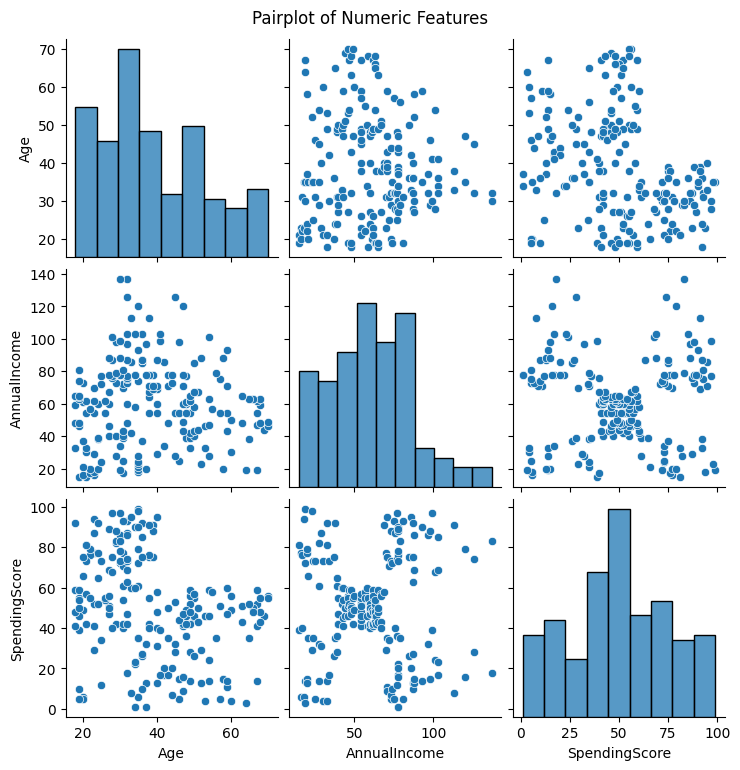

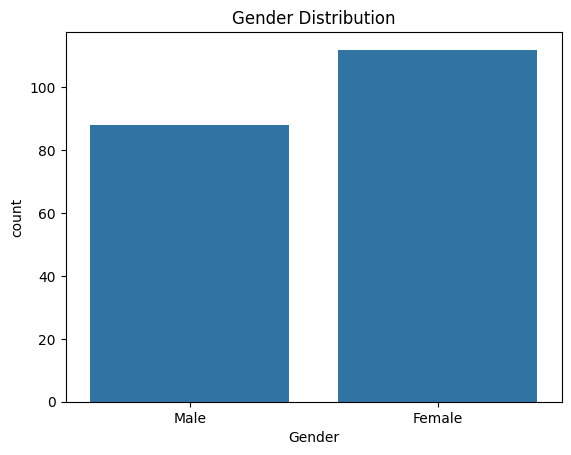

In [3]:
# ---- 3. Quick EDA before clustering ----
sns.pairplot(df[["Age", "AnnualIncome", "SpendingScore"]])
plt.suptitle("Pairplot of Numeric Features", y=1.02)
plt.show()

sns.countplot(x="Gender", data=df)
plt.title("Gender Distribution")
plt.show()

# ---- 4. Select features for unsupervised learning ----
# no target/label here - that's the whole point of unsupervised learning
X = df[["AnnualIncome", "SpendingScore"]]

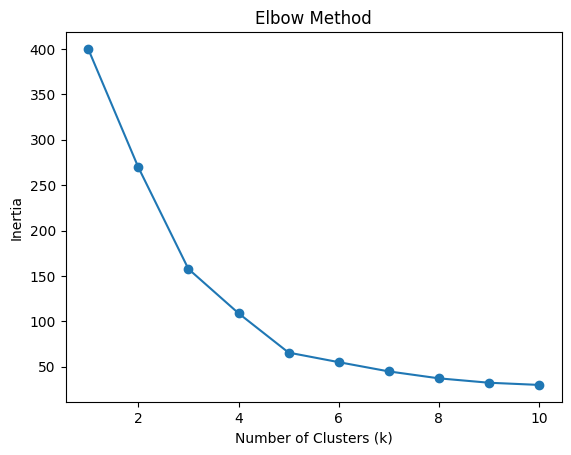

In [4]:
# ---- 5. Scale features ----
# distance-based algorithms (KMeans, hierarchical, DBSCAN) need scaled inputs
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---- 6. Find a good number of clusters (Elbow Method) ----
inertia = []
k_range = range(1, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.plot(k_range, inertia, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.show()

# elbow usually shows up around k=5 for this dataset

Cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64


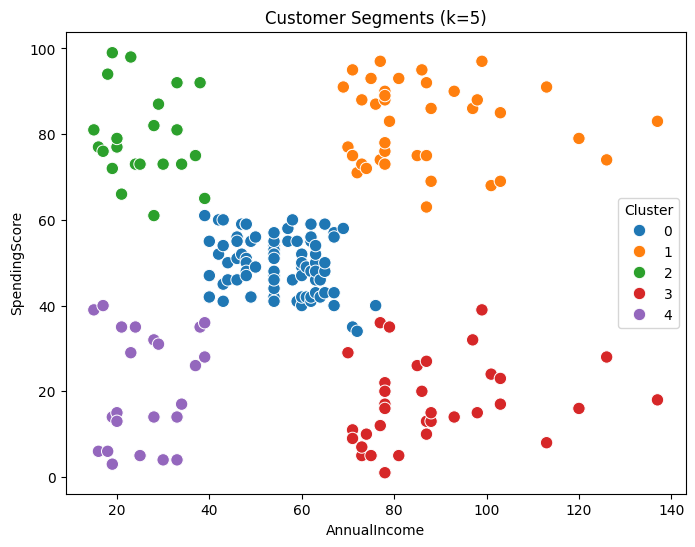

In [5]:
# ---- 7. Fit KMeans with chosen k ----
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df["Cluster"].value_counts())

# ---- 8. Visualize the clusters ----
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, x="AnnualIncome", y="SpendingScore",
    hue="Cluster", palette="tab10", s=80
)
plt.title(f"Customer Segments (k={k})")
plt.show()

In [ ]:

# ---- 9. Look at cluster profiles ----
# this is the actual business value of unsupervised learning here -
# understanding WHAT each cluster represents
cluster_summary = df.groupby("Cluster")[["Age", "AnnualIncome", "SpendingScore"]].mean()
print(cluster_summary)

# e.g. one cluster = high income, low spending (careful spenders)
# another = low income, high spending (potential risk / impulsive buyers)
# useful for targeted marketing

# ---- 10. Save segmented dataset ----
df.to_csv("mall_customers_segmented.csv", index=False)
print("Saved -> mall_customers_segmented.csv")